In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import random

random.seed(42)
np.random.seed(42)

logs = []

# Normal login activity
for i in range(100):
    logs.append({
        "timestamp": f"2026-11-03 10:{i % 60:02d}:00",
        "ip": f"192.168.1.{random.randint(2, 50)}",
        "username": random.choice(["alice", "bob", "charlie"]),
        "status": "SUCCESS"
    })

# Suspicious login activity
for i in range(30):
    logs.append({
        "timestamp": f"2026-11-03 11:{i % 60:02d}:00",
        "ip": "203.0.113.50",
        "username": "admin",
        "status": "FAILED"
    })

df = pd.DataFrame(logs)

print(len(logs))
print(df["status"].value_counts())

130
status
SUCCESS    100
FAILED      30
Name: count, dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  130 non-null    object
 1   ip         130 non-null    object
 2   username   130 non-null    object
 3   status     130 non-null    object
dtypes: object(4)
memory usage: 4.2+ KB


In [ ]:
df['status'].value_counts()

,count
status,
SUCCESS,100
FAILED,30


In [ ]:
df.groupby("ip")["status"].value_counts()

,,count
ip,status,
192.168.1.10,SUCCESS,1
192.168.1.11,SUCCESS,2
192.168.1.12,SUCCESS,3
192.168.1.16,SUCCESS,3
192.168.1.17,SUCCESS,1
192.168.1.18,SUCCESS,3
192.168.1.19,SUCCESS,3
192.168.1.2,SUCCESS,1
192.168.1.20,SUCCESS,1


In [ ]:
#count failed login attempts
failed_attempts=df[df['status']=='FAILED'].groupby("ip").size()
# Threshold for suspicious activity
threshold = 10
# Detect suspicious IPs
suspicious_ips = failed_attempts[failed_attempts >= threshold]

print("Suspicious IP Addresses:")

print(suspicious_ips)

Suspicious IP Addresses:
ip
203.0.113.50    30
dtype: int64


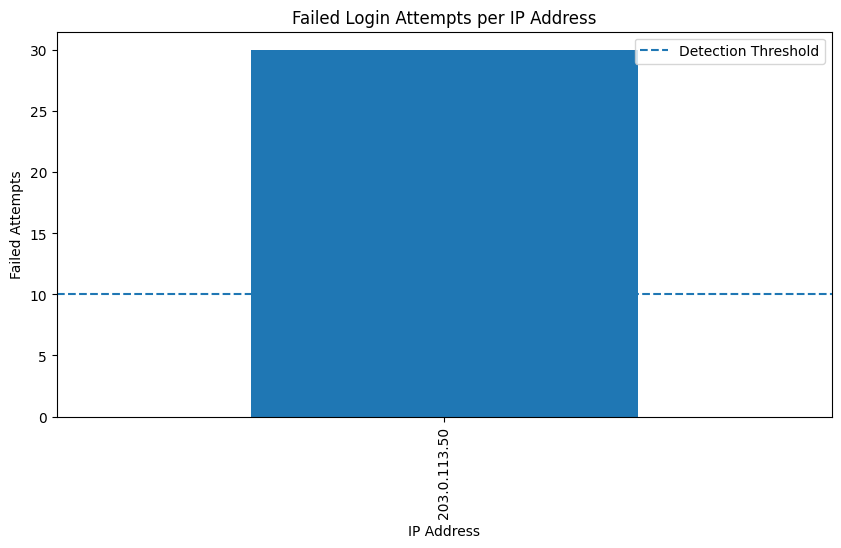

In [ ]:
#Visualize
import matplotlib.pyplot as plt

failed_attempts.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Failed Login Attempts per IP Address")
plt.xlabel("IP Address")
plt.ylabel("Failed Attempts")

plt.axhline(
    y=threshold,
    linestyle="--",
    label="Detection Threshold"
)

plt.legend()
plt.show()

In [ ]:

raw_logs = [
    "Nov  3 10:15:22 server sshd[1234]: Failed password for admin from 192.168.1.50 port 22 ssh2",

    "Nov  3 10:16:10 server sshd[1235]: Failed password for root from 192.168.1.50 port 22 ssh2",

    "Nov  3 10:17:05 server sshd[1236]: Accepted password for alice from 192.168.1.20 port 22 ssh2",

    "Nov  3 10:18:30 server sshd[1237]: Failed password for admin from 203.0.113.50 port 22 ssh2",

    "Nov  3 10:19:45 server sshd[1238]: Accepted password for bob from 192.168.1.25 port 22 ssh2"
]

for log in raw_logs:
    print(log)


Nov  3 10:15:22 server sshd[1234]: Failed password for admin from 192.168.1.50 port 22 ssh2
Nov  3 10:16:10 server sshd[1235]: Failed password for root from 192.168.1.50 port 22 ssh2
Nov  3 10:17:05 server sshd[1236]: Accepted password for alice from 192.168.1.20 port 22 ssh2
Nov  3 10:18:30 server sshd[1237]: Failed password for admin from 203.0.113.50 port 22 ssh2
Nov  3 10:19:45 server sshd[1238]: Accepted password for bob from 192.168.1.25 port 22 ssh2


In [ ]:

import re

log = raw_logs[0]

ip_pattern = r"\d+\.\d+\.\d+\.\d+"

ip = re.search(ip_pattern, log)

print(ip.group())


192.168.1.50


In [ ]:

log = raw_logs[0]

username_pattern = r"password for (\w+)"

username = re.search(username_pattern, log)

print(username.group(1))


admin


In [ ]:
log = raw_logs[1]

pattern = r"password for (\w+) from (\d+\.\d+\.\d+\.\d+)"

match = re.search(pattern, log)

print("Username:", match.group(1))
print("IP:", match.group(2))

Username: root
IP: 192.168.1.50


In [29]:

import re

def parse_log(log):

    pattern = r"(\w{3}\s+\d{1,2}\s+\d{2}:\d{2}:\d{2}).*sshd\[\d+\]: (Failed|Accepted) password for (\w+) from (\d+\.\d+\.\d+\.\d+)"

    match = re.search(pattern, log)

    if match:

        timestamp = match.group(1)
        status = match.group(2)
        username = match.group(3)
        ip = match.group(4)

        return {
            "timestamp": timestamp,
            "status": status.upper(),
            "username": username,
            "ip": ip
        }

    return None


In [28]:

parsed_log = parse_log(raw_logs[0])

print(parsed_log)


{'timestamp': 'Nov  3 10:15:22', 'status': 'FAILED', 'username': 'admin', 'ip': '192.168.1.50'}


In [30]:

parsed_logs = []

for log in raw_logs:

    result = parse_log(log)

    if result is not None:
        parsed_logs.append(result)

print("Total parsed logs:", len(parsed_logs))


Total parsed logs: 5


In [32]:

parsed_df = pd.DataFrame(parsed_logs)
parsed_df


,timestamp,status,username,ip
0,Nov 3 10:15:22,FAILED,admin,192.168.1.50
1,Nov 3 10:16:10,FAILED,root,192.168.1.50
2,Nov 3 10:17:05,ACCEPTED,alice,192.168.1.20
3,Nov 3 10:18:30,FAILED,admin,203.0.113.50
4,Nov 3 10:19:45,ACCEPTED,bob,192.168.1.25


In [33]:

from datetime import datetime, timedelta

attack_logs = []

start_time = datetime(2026, 11, 3, 10, 30, 0)

attacker_ip = "203.0.113.99"
target_username = "admin"

for i in range(12):

    timestamp = start_time + timedelta(seconds=20 * i)

    log = (
        f"{timestamp.strftime('%b %d %H:%M:%S')} "
        f"server sshd[{2000 + i}]: "
        f"Failed password for {target_username} "
        f"from {attacker_ip} port 22 ssh2"
    )

    attack_logs.append(log)

print("Generated attack logs:", len(attack_logs))


Generated attack logs: 12


In [34]:
#Combined with og logs
all_logs = raw_logs + attack_logs

parsed_logs = []

for log in all_logs:
    result = parse_log(log)

    if result is not None:
        parsed_logs.append(result)

parsed_df = pd.DataFrame(parsed_logs)

print("Total logs:", len(parsed_df))

parsed_df.tail(12)


Total logs: 17


,timestamp,status,username,ip
5,Nov 03 10:30:00,FAILED,admin,203.0.113.99
6,Nov 03 10:30:20,FAILED,admin,203.0.113.99
7,Nov 03 10:30:40,FAILED,admin,203.0.113.99
8,Nov 03 10:31:00,FAILED,admin,203.0.113.99
9,Nov 03 10:31:20,FAILED,admin,203.0.113.99
10,Nov 03 10:31:40,FAILED,admin,203.0.113.99
11,Nov 03 10:32:00,FAILED,admin,203.0.113.99
12,Nov 03 10:32:20,FAILED,admin,203.0.113.99
13,Nov 03 10:32:40,FAILED,admin,203.0.113.99
14,Nov 03 10:33:00,FAILED,admin,203.0.113.99


In [35]:

parsed_df["timestamp"] = pd.to_datetime(
    parsed_df["timestamp"] + " 2026",
    format="%b %d %H:%M:%S %Y"
)

parsed_df = parsed_df.sort_values("timestamp")

parsed_df.head()


,timestamp,status,username,ip
0,2026-11-03 10:15:22,FAILED,admin,192.168.1.50
1,2026-11-03 10:16:10,FAILED,root,192.168.1.50
2,2026-11-03 10:17:05,ACCEPTED,alice,192.168.1.20
3,2026-11-03 10:18:30,FAILED,admin,203.0.113.50
4,2026-11-03 10:19:45,ACCEPTED,bob,192.168.1.25


In [36]:

from datetime import timedelta

# Keep only failed login attempts
failed_df = parsed_df[parsed_df["status"] == "FAILED"]

alerts = []

# Analyze each IP address separately
for ip, group in failed_df.groupby("ip"):

    group = group.sort_values("timestamp")

    # Check each failed attempt as the end of a 5-minute window
    for current_time in group["timestamp"]:

        window_start = current_time - timedelta(minutes=5)

        attempts = group[
            (group["timestamp"] >= window_start) &
            (group["timestamp"] <= current_time)
        ]

        # Trigger an alert when 10 or more failures occur
        if len(attempts) >= 10:

            alerts.append({
                "ip": ip,
                "failed_attempts": len(attempts),
                "time_window": "5 minutes",
                "alert": "Possible Brute-Force Attack"
            })

            # One alert per IP for this basic version
            break

# Display alerts
alerts_df = pd.DataFrame(alerts)

alerts_df


,ip,failed_attempts,time_window,alert
0,203.0.113.99,10,5 minutes,Possible Brute-Force Attack


In [37]:

# Count failed login attempts from each IP
failed_attempt_counts = (
    parsed_df[parsed_df["status"] == "FAILED"]
    .groupby("ip")
    .size()
    .reset_index(name="failed_attempts")
)

failed_attempt_counts


,ip,failed_attempts
0,192.168.1.50,2
1,203.0.113.50,1
2,203.0.113.99,12


In [38]:

# Apply our threshold
failed_attempt_counts["status"] = failed_attempt_counts[
    "failed_attempts"
].apply(
    lambda count: "SUSPICIOUS" if count >= 10 else "NORMAL"
)

failed_attempt_counts


,ip,failed_attempts,status
0,192.168.1.50,2,NORMAL
1,203.0.113.50,1,NORMAL
2,203.0.113.99,12,SUSPICIOUS


In [40]:

print("===== LOG-BASED THREAT DETECTOR =====")
print()

for _, row in failed_attempt_counts.iterrows():

    if row["status"] == "SUSPICIOUS":

        print("SECURITY ALERT")
        print("IP Address:", row["ip"])
        print("Failed Attempts:", row["failed_attempts"])
        print("Status:", row["status"])
        print("-----------------------------")

    else:

        print("IP Address:", row["ip"])
        print("Failed Attempts:", row["failed_attempts"])
        print("Status:", row["status"])
        print("-----------------------------")


===== LOG-BASED THREAT DETECTOR =====

IP Address: 192.168.1.50
Failed Attempts: 2
Status: NORMAL
-----------------------------
IP Address: 203.0.113.50
Failed Attempts: 1
Status: NORMAL
-----------------------------
SECURITY ALERT
IP Address: 203.0.113.99
Failed Attempts: 12
Status: SUSPICIOUS
-----------------------------


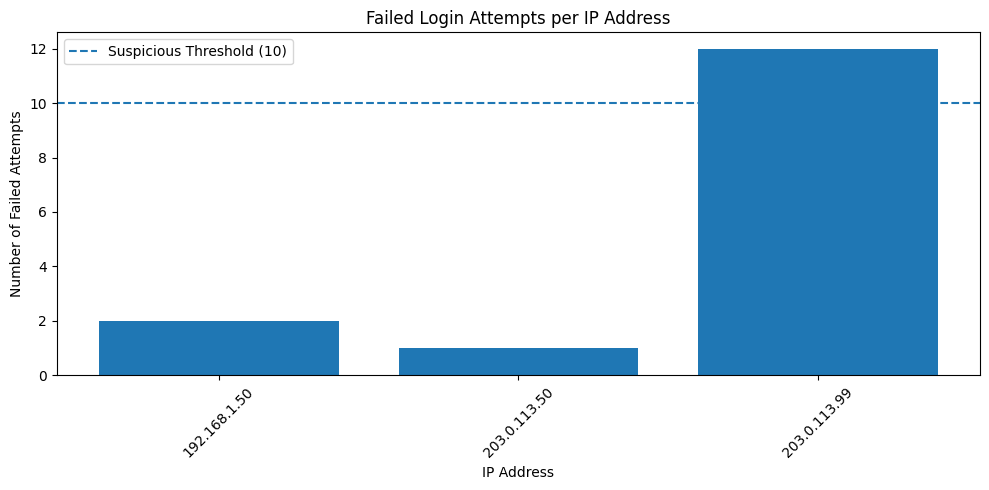

In [41]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    failed_attempt_counts["ip"],
    failed_attempt_counts["failed_attempts"]
)

plt.axhline(
    y=10,
    linestyle="--",
    label="Suspicious Threshold (10)"
)

plt.title("Failed Login Attempts per IP Address")
plt.xlabel("IP Address")
plt.ylabel("Number of Failed Attempts")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


 **ML Intro**

In [42]:

# Count failed attempts per IP
failed_counts = (
    parsed_df[parsed_df["status"] == "FAILED"]
    .groupby("ip")
    .size()
)

# Count successful attempts per IP
success_counts = (
    parsed_df[parsed_df["status"] == "ACCEPTED"]
    .groupby("ip")
    .size()
)

# Combine both counts into one table
ip_features = pd.DataFrame({
    "failed_attempts": failed_counts,
    "successful_attempts": success_counts
}).fillna(0)

# Calculate total login attempts
ip_features["total_attempts"] = (
    ip_features["failed_attempts"] +
    ip_features["successful_attempts"]
)

# Calculate failure rate
ip_features["failure_rate"] = (
    ip_features["failed_attempts"] /
    ip_features["total_attempts"]
)

ip_features


,failed_attempts,successful_attempts,total_attempts,failure_rate
ip,,,,
192.168.1.20,0.0,1.0,1.0,0.0
192.168.1.25,0.0,1.0,1.0,0.0
192.168.1.50,2.0,0.0,2.0,1.0
203.0.113.50,1.0,0.0,1.0,1.0
203.0.113.99,12.0,0.0,12.0,1.0


In [43]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Select numerical features
X = ip_features[
    [
        "failed_attempts",
        "successful_attempts",
        "total_attempts",
        "failure_rate"
    ]
]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create the Isolation Forest model
model = IsolationForest(
    contamination=0.2,
    random_state=42
)

# Train and predict anomalies
ip_features["ml_prediction"] = model.fit_predict(X_scaled)

# Convert predictions into readable labels
ip_features["ml_status"] = ip_features["ml_prediction"].apply(
    lambda value: "ANOMALY" if value == -1 else "NORMAL"
)

ip_features


,failed_attempts,successful_attempts,total_attempts,failure_rate,ml_prediction,ml_status
ip,,,,,,
192.168.1.20,0.0,1.0,1.0,0.0,1,NORMAL
192.168.1.25,0.0,1.0,1.0,0.0,1,NORMAL
192.168.1.50,2.0,0.0,2.0,1.0,1,NORMAL
203.0.113.50,1.0,0.0,1.0,1.0,1,NORMAL
203.0.113.99,12.0,0.0,12.0,1.0,-1,ANOMALY


In [44]:

# Add the rule-based detection result to our ML features

ip_features["rule_status"] = ip_features["failed_attempts"].apply(
    lambda count: "SUSPICIOUS" if count >= 10 else "NORMAL"
)

ip_features


,failed_attempts,successful_attempts,total_attempts,failure_rate,ml_prediction,ml_status,rule_status
ip,,,,,,,
192.168.1.20,0.0,1.0,1.0,0.0,1,NORMAL,NORMAL
192.168.1.25,0.0,1.0,1.0,0.0,1,NORMAL,NORMAL
192.168.1.50,2.0,0.0,2.0,1.0,1,NORMAL,NORMAL
203.0.113.50,1.0,0.0,1.0,1.0,1,NORMAL,NORMAL
203.0.113.99,12.0,0.0,12.0,1.0,-1,ANOMALY,SUSPICIOUS


In [45]:

def get_final_status(row):

    if (
        row["rule_status"] == "SUSPICIOUS"
        or row["ml_status"] == "ANOMALY"
    ):
        return "SUSPICIOUS"

    return "NORMAL"


ip_features["final_status"] = ip_features.apply(
    get_final_status,
    axis=1
)

ip_features


,failed_attempts,successful_attempts,total_attempts,failure_rate,ml_prediction,ml_status,rule_status,final_status
ip,,,,,,,,
192.168.1.20,0.0,1.0,1.0,0.0,1,NORMAL,NORMAL,NORMAL
192.168.1.25,0.0,1.0,1.0,0.0,1,NORMAL,NORMAL,NORMAL
192.168.1.50,2.0,0.0,2.0,1.0,1,NORMAL,NORMAL,NORMAL
203.0.113.50,1.0,0.0,1.0,1.0,1,NORMAL,NORMAL,NORMAL
203.0.113.99,12.0,0.0,12.0,1.0,-1,ANOMALY,SUSPICIOUS,SUSPICIOUS


In [47]:

print("======================================")
print("     LOG-BASED THREAT DETECTOR")
print("======================================")

for ip, row in ip_features.iterrows():

    print("\nIP Address:", ip)
    print("Failed Attempts:", int(row["failed_attempts"]))
    print("Successful Attempts:", int(row["successful_attempts"]))
    print("Rule-Based Result:", row["rule_status"])
    print("ML Result:", row["ml_status"])
    print("Final Status:", row["final_status"])

    if row["final_status"] == "SUSPICIOUS":
        print("🚨 ALERT: Suspicious activity detected!")
    else:
        print("✅ No anomaly detected by current checks.")


     LOG-BASED THREAT DETECTOR

IP Address: 192.168.1.20
Failed Attempts: 0
Successful Attempts: 1
Rule-Based Result: NORMAL
ML Result: NORMAL
Final Status: NORMAL
✅ No anomaly detected by current checks.

IP Address: 192.168.1.25
Failed Attempts: 0
Successful Attempts: 1
Rule-Based Result: NORMAL
ML Result: NORMAL
Final Status: NORMAL
✅ No anomaly detected by current checks.

IP Address: 192.168.1.50
Failed Attempts: 2
Successful Attempts: 0
Rule-Based Result: NORMAL
ML Result: NORMAL
Final Status: NORMAL
✅ No anomaly detected by current checks.

IP Address: 203.0.113.50
Failed Attempts: 1
Successful Attempts: 0
Rule-Based Result: NORMAL
ML Result: NORMAL
Final Status: NORMAL
✅ No anomaly detected by current checks.

IP Address: 203.0.113.99
Failed Attempts: 12
Successful Attempts: 0
Rule-Based Result: SUSPICIOUS
ML Result: ANOMALY
Final Status: SUSPICIOUS
🚨 ALERT: Suspicious activity detected!


In [48]:
#Loghub ssh dataset

!wget -O SSH.tar.gz "https://zenodo.org/records/8196385/files/SSH.tar.gz?download=1"


--2026-11-03 10:41:34--  https://zenodo.org/records/8196385/files/SSH.tar.gz?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.42.113, 188.185.45.63, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4596666 (4.4M) [application/octet-stream]
Saving to: ‘SSH.tar.gz’

SSH.tar.gz          100%[===================>]   4.38M   882KB/s    in 5.3s    

2026-11-03 10:41:40 (848 KB/s) - ‘SSH.tar.gz’ saved [4596666/4596666]



In [49]:

import tarfile
import os

with tarfile.open("SSH.tar.gz", "r:gz") as tar:
    tar.extractall("openssh_data")

print("Dataset extracted successfully!")


/tmp/ipykernel_1280/477329857.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("openssh_data")


Dataset extracted successfully!


In [50]:

for root, dirs, files in os.walk("openssh_data"):
    for file in files:
        print(os.path.join(root, file))


openssh_data/SSH.log


In [51]:

import os

log_files = []

for root, dirs, files in os.walk("openssh_data"):
    for file in files:
        if file.endswith(".log") or file.endswith(".txt"):
            log_files.append(os.path.join(root, file))

print("Found log files:")
for file in log_files:
    print(file)


Found log files:
openssh_data/SSH.log


In [52]:

# Select the first log file
log_file = log_files[0]

print("Selected file:", log_file)
print("\nFirst 10 log lines:\n")

with open(log_file, "r", encoding="utf-8", errors="ignore") as f:
    for i in range(10):
        line = f.readline()
        if not line:
            break
        print(line.strip())


Selected file: openssh_data/SSH.log

First 10 log lines:

Dec 10 06:55:46 LabSZ sshd[24200]: reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!
Dec 10 06:55:46 LabSZ sshd[24200]: Invalid user webmaster from 173.234.31.186
Dec 10 06:55:46 LabSZ sshd[24200]: input_userauth_request: invalid user webmaster [preauth]
Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): check pass; user unknown
Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186
Dec 10 06:55:48 LabSZ sshd[24200]: Failed password for invalid user webmaster from 173.234.31.186 port 38926 ssh2
Dec 10 06:55:48 LabSZ sshd[24200]: Connection closed by 173.234.31.186 [preauth]
Dec 10 07:02:47 LabSZ sshd[24203]: Connection closed by 212.47.254.145 [preauth]
Dec 10 07:07:38 LabSZ sshd[24206]: Invalid user test9 from 52.80.34.196
Dec 10 07:07:38 LabSZ sshd[24206]: input_userauth_req

In [53]:

with open(log_file, "r", encoding="utf-8", errors="ignore") as f:
    real_logs = [line.strip() for line in f if line.strip()]

print("Total log entries:", len(real_logs))


Total log entries: 655147


In [55]:
#create parser

import re

def parse_real_ssh_log(log):

    # Extract timestamp
    timestamp_pattern = r"^(\w{3}\s+\d{1,2}\s+\d{2}:\d{2}:\d{2})"
    timestamp_match = re.search(timestamp_pattern, log)

    timestamp = timestamp_match.group(1) if timestamp_match else None

    # Extract source IP address
    ip_pattern = r"\b(?:\d{1,3}\.){3}\d{1,3}\b"
    ip_match = re.search(ip_pattern, log)

    ip = ip_match.group() if ip_match else None

    # Extract username
    username = None

    invalid_user_match = re.search(r"Invalid user (\S+)", log)

    failed_password_match = re.search(
        r"Failed password for (?:invalid user )?(\S+) from",
        log
    )

    accepted_password_match = re.search(
        r"Accepted password for (\S+) from",
        log
    )

    if invalid_user_match:
        username = invalid_user_match.group(1)

    elif failed_password_match:
        username = failed_password_match.group(1)

    elif accepted_password_match:
        username = accepted_password_match.group(1)

    # Classify the event
    if "POSSIBLE BREAK-IN ATTEMPT" in log:
        event_type = "SUSPICIOUS_ACTIVITY"

    elif "Failed password" in log:
        event_type = "FAILED_LOGIN"

    elif "Invalid user" in log:
        event_type = "INVALID_USER"

    elif "Accepted password" in log:
        event_type = "SUCCESSFUL_LOGIN"

    elif "authentication failure" in log:
        event_type = "AUTHENTICATION_FAILURE"

    elif "Connection closed" in log:
        event_type = "CONNECTION_CLOSED"

    else:
        event_type = "OTHER"

    return {
        "timestamp": timestamp,
        "event_type": event_type,
        "username": username,
        "ip": ip,
        "raw_log": log
    }


In [56]:

for log in real_logs[:10]:

    parsed = parse_real_ssh_log(log)

    print(parsed)
    print("-" * 80)


{'timestamp': 'Dec 10 06:55:46', 'event_type': 'SUSPICIOUS_ACTIVITY', 'username': None, 'ip': '173.234.31.186', 'raw_log': 'Dec 10 06:55:46 LabSZ sshd[24200]: reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!'}
--------------------------------------------------------------------------------
{'timestamp': 'Dec 10 06:55:46', 'event_type': 'INVALID_USER', 'username': 'webmaster', 'ip': '173.234.31.186', 'raw_log': 'Dec 10 06:55:46 LabSZ sshd[24200]: Invalid user webmaster from 173.234.31.186'}
--------------------------------------------------------------------------------
{'timestamp': 'Dec 10 06:55:46', 'event_type': 'OTHER', 'username': None, 'ip': None, 'raw_log': 'Dec 10 06:55:46 LabSZ sshd[24200]: input_userauth_request: invalid user webmaster [preauth]'}
--------------------------------------------------------------------------------
{'timestamp': 'Dec 10 06:55:46', 'event_type': 'OTHER', 'username': None, 'ip': Non

In [57]:

real_parsed_logs = [
    parse_real_ssh_log(log)
    for log in real_logs
]

real_df = pd.DataFrame(real_parsed_logs)

print("Total parsed entries:", len(real_df))

real_df.head(10)


Total parsed entries: 655147


,timestamp,event_type,username,ip,raw_log
0,Dec 10 06:55:46,SUSPICIOUS_ACTIVITY,None,173.234.31.186,Dec 10 06:55:46 LabSZ sshd[24200]: reverse map...
1,Dec 10 06:55:46,INVALID_USER,webmaster,173.234.31.186,Dec 10 06:55:46 LabSZ sshd[24200]: Invalid use...
2,Dec 10 06:55:46,OTHER,None,None,Dec 10 06:55:46 LabSZ sshd[24200]: input_usera...
3,Dec 10 06:55:46,OTHER,None,None,Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(ss...
4,Dec 10 06:55:46,AUTHENTICATION_FAILURE,None,173.234.31.186,Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(ss...
5,Dec 10 06:55:48,FAILED_LOGIN,webmaster,173.234.31.186,Dec 10 06:55:48 LabSZ sshd[24200]: Failed pass...
6,Dec 10 06:55:48,CONNECTION_CLOSED,None,173.234.31.186,Dec 10 06:55:48 LabSZ sshd[24200]: Connection ...
7,Dec 10 07:02:47,CONNECTION_CLOSED,None,212.47.254.145,Dec 10 07:02:47 LabSZ sshd[24203]: Connection ...
8,Dec 10 07:07:38,INVALID_USER,test9,52.80.34.196,Dec 10 07:07:38 LabSZ sshd[24206]: Invalid use...
9,Dec 10 07:07:38,OTHER,None,None,Dec 10 07:07:38 LabSZ sshd[24206]: input_usera...


In [58]:

real_df["event_type"].value_counts()


,count
event_type,
AUTHENTICATION_FAILURE,230673
FAILED_LOGIN,197587
OTHER,123747
CONNECTION_CLOSED,68958
SUSPICIOUS_ACTIVITY,19406
INVALID_USER,14594
SUCCESSFUL_LOGIN,182


In [59]:

# Convert timestamps into datetime format
real_df["timestamp"] = pd.to_datetime(
    real_df["timestamp"] + " 2026",
    format="%b %d %H:%M:%S %Y",
    errors="coerce"
)

# Remove entries with missing timestamps or IP addresses
real_df = real_df.dropna(subset=["timestamp", "ip"])

# Sort logs chronologically
real_df = real_df.sort_values("timestamp")

print("Cleaned log entries:", len(real_df))

real_df.head()


Cleaned log entries: 542861


,timestamp,event_type,username,ip,raw_log
302278,2026-01-01 00:12:28,AUTHENTICATION_FAILURE,None,74.82.254.191,Jan 1 00:12:28 LabSZ sshd[3117]: pam_unix(ssh...
302277,2026-01-01 00:12:28,SUSPICIOUS_ACTIVITY,None,74.82.254.191,Jan 1 00:12:28 LabSZ sshd[3117]: reverse mapp...
302279,2026-01-01 00:12:30,FAILED_LOGIN,root,74.82.254.191,Jan 1 00:12:30 LabSZ sshd[3117]: Failed passw...
302282,2026-01-01 00:12:43,AUTHENTICATION_FAILURE,None,74.82.254.191,Jan 1 00:12:43 LabSZ sshd[3117]: PAM 5 more a...
302280,2026-01-01 00:12:43,FAILED_LOGIN,root,74.82.254.191,Jan 1 00:12:43 LabSZ sshd[3117]: message repe...


In [60]:

# Infer year changes from the chronological raw log order

month_numbers = {
    "Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4,
    "May": 5, "Jun": 6, "Jul": 7, "Aug": 8,
    "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12
}

timestamps = []
current_year = 2026
previous_month = None

for log in real_df["raw_log"]:

    match = re.match(
        r"^(\w{3}\s+\d{1,2}\s+\d{2}:\d{2}:\d{2})",
        log
    )

    if match:
        timestamp_text = match.group(1)
        month_text = timestamp_text[:3]
        month_num = month_numbers[month_text]

        # Detect December -> January rollover
        if previous_month is not None and month_num < previous_month:
            current_year += 1

        previous_month = month_num

        full_timestamp = pd.to_datetime(
            timestamp_text + f" {current_year}",
            format="%b %d %H:%M:%S %Y"
        )

        timestamps.append(full_timestamp)

    else:
        timestamps.append(pd.NaT)

real_df["timestamp"] = timestamps

real_df = real_df.sort_values("timestamp")

real_df[["timestamp", "event_type", "username", "ip"]].head()


,timestamp,event_type,username,ip
302278,2026-01-01 00:12:28,AUTHENTICATION_FAILURE,None,74.82.254.191
302277,2026-01-01 00:12:28,SUSPICIOUS_ACTIVITY,None,74.82.254.191
302279,2026-01-01 00:12:30,FAILED_LOGIN,root,74.82.254.191
302282,2026-01-01 00:12:43,AUTHENTICATION_FAILURE,None,74.82.254.191
302280,2026-01-01 00:12:43,FAILED_LOGIN,root,74.82.254.191


In [61]:

failed_df = real_df[
    real_df["event_type"] == "FAILED_LOGIN"
][["timestamp", "ip"]].dropna()

print("Failed password events:", len(failed_df))

failed_df.head()


Failed password events: 197587


,timestamp,ip
302279,2026-01-01 00:12:30,74.82.254.191
302280,2026-01-01 00:12:43,74.82.254.191
302288,2026-01-01 00:15:58,188.166.228.127
302294,2026-01-01 00:16:02,188.166.228.127
302297,2026-01-01 00:16:06,188.166.228.127


In [62]:

from datetime import timedelta

threshold = 10
window = "5min"

brute_force_alerts = []

for ip, group in failed_df.groupby("ip"):

    # Sort this IP's failed attempts by time
    times = group["timestamp"].sort_values()

    # Create a rolling count of attempts within 5 minutes
    rolling_counts = pd.Series(
        1,
        index=pd.DatetimeIndex(times)
    ).rolling(window).sum()

    # Find the highest count in any 5-minute window
    max_attempts = int(rolling_counts.max())

    if max_attempts >= threshold:

        brute_force_alerts.append({
            "ip": ip,
            "max_failed_attempts": max_attempts,
            "time_window": window,
            "alert": "POSSIBLE BRUTE-FORCE ATTACK"
        })

brute_force_df = pd.DataFrame(brute_force_alerts)

brute_force_df = brute_force_df.sort_values(
    "max_failed_attempts",
    ascending=False
)

brute_force_df


,ip,max_failed_attempts,time_window,alert
85,183.63.110.206,160,5min,POSSIBLE BRUTE-FORCE ATTACK
158,60.2.12.12,160,5min,POSSIBLE BRUTE-FORCE ATTACK
86,183.63.172.52,152,5min,POSSIBLE BRUTE-FORCE ATTACK
83,183.62.140.253,150,5min,POSSIBLE BRUTE-FORCE ATTACK
27,119.1.109.20,150,5min,POSSIBLE BRUTE-FORCE ATTACK
...,...,...,...,...
110,209.250.242.125,10,5min,POSSIBLE BRUTE-FORCE ATTACK
112,209.250.242.40,10,5min,POSSIBLE BRUTE-FORCE ATTACK
111,209.250.242.246,10,5min,POSSIBLE BRUTE-FORCE ATTACK
143,45.77.138.41,10,5min,POSSIBLE BRUTE-FORCE ATTACK


In [63]:

print("===== REAL SSH BRUTE-FORCE DETECTION =====")

print("Total failed password events:", len(failed_df))
print("Suspicious IPs detected:", len(brute_force_df))

if len(brute_force_df) > 0:

    print("\n🚨 Suspicious IP addresses:")

    display(brute_force_df)

else:

    print("\nNo IP crossed the current threshold.")


===== REAL SSH BRUTE-FORCE DETECTION =====
Total failed password events: 197587
Suspicious IPs detected: 175

🚨 Suspicious IP addresses:


,ip,max_failed_attempts,time_window,alert
85,183.63.110.206,160,5min,POSSIBLE BRUTE-FORCE ATTACK
158,60.2.12.12,160,5min,POSSIBLE BRUTE-FORCE ATTACK
86,183.63.172.52,152,5min,POSSIBLE BRUTE-FORCE ATTACK
83,183.62.140.253,150,5min,POSSIBLE BRUTE-FORCE ATTACK
27,119.1.109.20,150,5min,POSSIBLE BRUTE-FORCE ATTACK
...,...,...,...,...
110,209.250.242.125,10,5min,POSSIBLE BRUTE-FORCE ATTACK
112,209.250.242.40,10,5min,POSSIBLE BRUTE-FORCE ATTACK
111,209.250.242.246,10,5min,POSSIBLE BRUTE-FORCE ATTACK
143,45.77.138.41,10,5min,POSSIBLE BRUTE-FORCE ATTACK


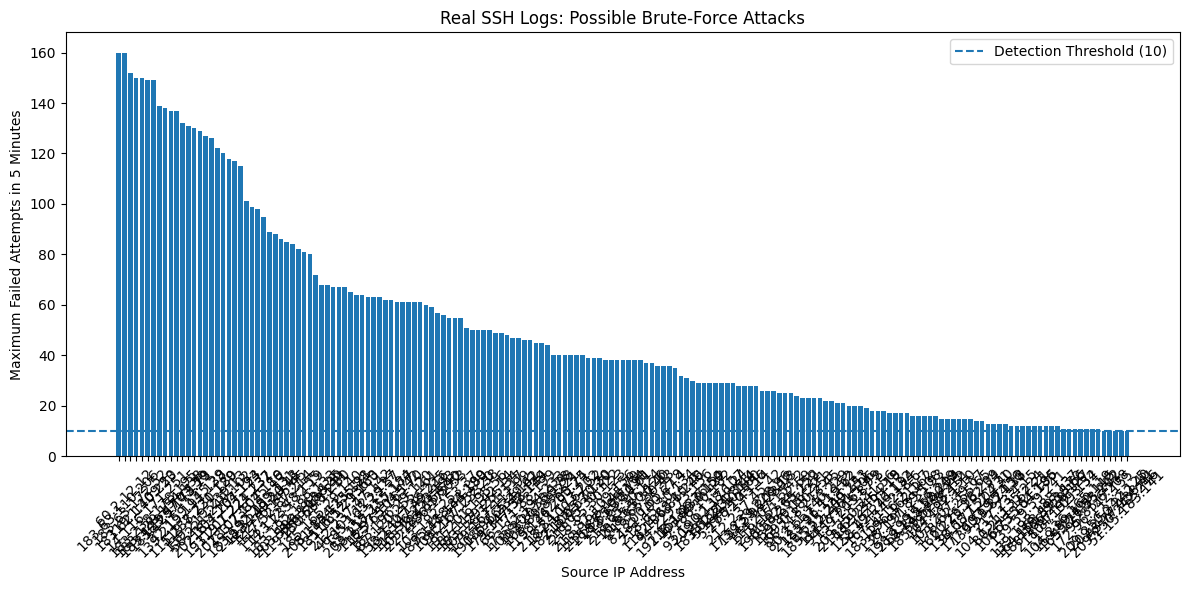

In [64]:

import matplotlib.pyplot as plt

if not brute_force_df.empty:

    plt.figure(figsize=(12, 6))

    plt.bar(
        brute_force_df["ip"],
        brute_force_df["max_failed_attempts"]
    )

    plt.axhline(
        y=10,
        linestyle="--",
        label="Detection Threshold (10)"
    )

    plt.title("Real SSH Logs: Possible Brute-Force Attacks")
    plt.xlabel("Source IP Address")
    plt.ylabel("Maximum Failed Attempts in 5 Minutes")

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("No suspicious IPs to visualize.")


In [65]:

if not brute_force_df.empty:

    brute_force_df["mitre_technique_id"] = "T1110"
    brute_force_df["mitre_technique_name"] = "Brute Force"
    brute_force_df["mitre_tactic"] = "Credential Access"

    brute_force_df["severity"] = brute_force_df[
        "max_failed_attempts"
    ].apply(
        lambda count: "HIGH" if count >= 20 else "MEDIUM"
    )

brute_force_df


,ip,max_failed_attempts,time_window,alert,mitre_technique_id,mitre_technique_name,mitre_tactic,severity
85,183.63.110.206,160,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH
158,60.2.12.12,160,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH
86,183.63.172.52,152,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH
83,183.62.140.253,150,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH
27,119.1.109.20,150,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH
...,...,...,...,...,...,...,...,...
110,209.250.242.125,10,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,MEDIUM
112,209.250.242.40,10,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,MEDIUM
111,209.250.242.246,10,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,MEDIUM
143,45.77.138.41,10,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,MEDIUM


In [66]:

for _, alert in brute_force_df.iterrows():

    print("=" * 50)
    print("🚨 SECURITY ALERT")
    print("=" * 50)

    print("Source IP:", alert["ip"])
    print("Failed Attempts:", alert["max_failed_attempts"])
    print("Detection Window:", alert["time_window"])
    print("Severity:", alert["severity"])

    print("\nMITRE ATT&CK Mapping")
    print("Technique ID:", alert["mitre_technique_id"])
    print("Technique:", alert["mitre_technique_name"])
    print("Tactic:", alert["mitre_tactic"])

    print("=" * 50)


🚨 SECURITY ALERT
Source IP: 183.63.110.206
Failed Attempts: 160
Detection Window: 5min
Severity: HIGH

MITRE ATT&CK Mapping
Technique ID: T1110
Technique: Brute Force
Tactic: Credential Access
🚨 SECURITY ALERT
Source IP: 60.2.12.12
Failed Attempts: 160
Detection Window: 5min
Severity: HIGH

MITRE ATT&CK Mapping
Technique ID: T1110
Technique: Brute Force
Tactic: Credential Access
🚨 SECURITY ALERT
Source IP: 183.63.172.52
Failed Attempts: 152
Detection Window: 5min
Severity: HIGH

MITRE ATT&CK Mapping
Technique ID: T1110
Technique: Brute Force
Tactic: Credential Access
🚨 SECURITY ALERT
Source IP: 183.62.140.253
Failed Attempts: 150
Detection Window: 5min
Severity: HIGH

MITRE ATT&CK Mapping
Technique ID: T1110
Technique: Brute Force
Tactic: Credential Access
🚨 SECURITY ALERT
Source IP: 119.1.109.20
Failed Attempts: 150
Detection Window: 5min
Severity: HIGH

MITRE ATT&CK Mapping
Technique ID: T1110
Technique: Brute Force
Tactic: Credential Access
🚨 SECURITY ALERT
Source IP: 14.116.171.251

In [67]:
#tackling password spraying
# Select failed logins with a known username and IP
spray_df = real_df[
    (real_df["event_type"] == "FAILED_LOGIN")
    & real_df["username"].notna()
    & real_df["ip"].notna()
][["timestamp", "ip", "username"]].copy()

spray_df = spray_df.sort_values("timestamp")

print("Failed logins available for analysis:", len(spray_df))

spray_df.head()


Failed logins available for analysis: 197394


,timestamp,ip,username
302279,2026-01-01 00:12:30,74.82.254.191,root
302280,2026-01-01 00:12:43,74.82.254.191,root
302288,2026-01-01 00:15:58,188.166.228.127,ubnt
302294,2026-01-01 00:16:02,188.166.228.127,admin
302297,2026-01-01 00:16:06,188.166.228.127,root


In [68]:

from collections import Counter
import pandas as pd

username_threshold = 10
window_duration = pd.Timedelta(minutes=5)

spray_alerts = []

for ip, group in spray_df.groupby("ip"):

    group = group.sort_values("timestamp")

    times = group["timestamp"].tolist()
    usernames = group["username"].tolist()

    active_usernames = Counter()
    left = 0

    for right in range(len(times)):

        # Add current username to the active window
        active_usernames[usernames[right]] += 1

        # Remove entries older than 5 minutes
        while times[right] - times[left] > window_duration:

            old_username = usernames[left]
            active_usernames[old_username] -= 1

            if active_usernames[old_username] == 0:

                del active_usernames[old_username]

            left += 1

        # Count distinct usernames in the current window
        distinct_usernames = len(active_usernames)

        if distinct_usernames >= username_threshold:

            spray_alerts.append({
                "ip": ip,
                "distinct_usernames": distinct_usernames,
                "time_window": "5 minutes",
                "alert": "POSSIBLE PASSWORD SPRAYING"
            })

            # One alert per IP for this basic version
            break

spray_alerts_df = pd.DataFrame(spray_alerts)

spray_alerts_df


,ip,distinct_usernames,time_window,alert
0,1.34.138.144,10,5 minutes,POSSIBLE PASSWORD SPRAYING
1,103.207.38.178,10,5 minutes,POSSIBLE PASSWORD SPRAYING
2,103.207.39.38,10,5 minutes,POSSIBLE PASSWORD SPRAYING
3,103.217.152.20,10,5 minutes,POSSIBLE PASSWORD SPRAYING
4,103.224.166.40,10,5 minutes,POSSIBLE PASSWORD SPRAYING
...,...,...,...,...
65,87.120.255.161,10,5 minutes,POSSIBLE PASSWORD SPRAYING
66,93.190.138.107,10,5 minutes,POSSIBLE PASSWORD SPRAYING
67,94.167.233.38,10,5 minutes,POSSIBLE PASSWORD SPRAYING
68,94.177.161.99,10,5 minutes,POSSIBLE PASSWORD SPRAYING


In [69]:

if not spray_alerts_df.empty:

    spray_alerts_df["mitre_technique_id"] = "T1110.003"
    spray_alerts_df["mitre_technique_name"] = "Password Spraying"
    spray_alerts_df["mitre_tactic"] = "Credential Access"
    spray_alerts_df["severity"] = "HIGH"

spray_alerts_df


,ip,distinct_usernames,time_window,alert,mitre_technique_id,mitre_technique_name,mitre_tactic,severity
0,1.34.138.144,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
1,103.207.38.178,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
2,103.207.39.38,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
3,103.217.152.20,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
4,103.224.166.40,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
...,...,...,...,...,...,...,...,...
65,87.120.255.161,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
66,93.190.138.107,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
67,94.167.233.38,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH
68,94.177.161.99,10,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH


In [70]:

alert_frames = []

# Add brute-force alerts
if not brute_force_df.empty:

    brute_force_report = brute_force_df.copy()
    brute_force_report["detection_type"] = "Brute Force"

    alert_frames.append(brute_force_report)


# Add password-spraying alerts
if not spray_alerts_df.empty:

    password_spray_report = spray_alerts_df.copy()
    password_spray_report["detection_type"] = "Password Spraying"

    alert_frames.append(password_spray_report)


# Combine all alert types
if alert_frames:

    unified_alerts_df = pd.concat(
        alert_frames,
        ignore_index=True
    )

else:

    unified_alerts_df = pd.DataFrame()


unified_alerts_df


,ip,max_failed_attempts,time_window,alert,mitre_technique_id,mitre_technique_name,mitre_tactic,severity,detection_type,distinct_usernames
0,183.63.110.206,160.0,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH,Brute Force,NaN
1,60.2.12.12,160.0,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH,Brute Force,NaN
2,183.63.172.52,152.0,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH,Brute Force,NaN
3,183.62.140.253,150.0,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH,Brute Force,NaN
4,119.1.109.20,150.0,5min,POSSIBLE BRUTE-FORCE ATTACK,T1110,Brute Force,Credential Access,HIGH,Brute Force,NaN
...,...,...,...,...,...,...,...,...,...,...
240,87.120.255.161,NaN,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH,Password Spraying,10.0
241,93.190.138.107,NaN,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH,Password Spraying,10.0
242,94.167.233.38,NaN,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH,Password Spraying,10.0
243,94.177.161.99,NaN,5 minutes,POSSIBLE PASSWORD SPRAYING,T1110.003,Password Spraying,Credential Access,HIGH,Password Spraying,10.0


In [71]:

print("=" * 60)
print("       LOG-BASED THREAT DETECTOR")
print("          UNIFIED SECURITY REPORT")
print("=" * 60)

if unified_alerts_df.empty:

    print("No suspicious activity detected.")

else:

    print("Total alerts:", len(unified_alerts_df))

    for _, alert in unified_alerts_df.iterrows():

        print("\n🚨 ALERT")
        print("-" * 40)

        print("Detection Type:", alert["detection_type"])
        print("Source IP:", alert["ip"])
        print("Severity:", alert["severity"])
        print("MITRE Technique:", alert["mitre_technique_id"])
        print("Technique Name:", alert["mitre_technique_name"])
        print("Tactic:", alert["mitre_tactic"])

print("\n" + "=" * 60)


       LOG-BASED THREAT DETECTOR
          UNIFIED SECURITY REPORT
Total alerts: 245

🚨 ALERT
----------------------------------------
Detection Type: Brute Force
Source IP: 183.63.110.206
Severity: HIGH
MITRE Technique: T1110
Technique Name: Brute Force
Tactic: Credential Access

🚨 ALERT
----------------------------------------
Detection Type: Brute Force
Source IP: 60.2.12.12
Severity: HIGH
MITRE Technique: T1110
Technique Name: Brute Force
Tactic: Credential Access

🚨 ALERT
----------------------------------------
Detection Type: Brute Force
Source IP: 183.63.172.52
Severity: HIGH
MITRE Technique: T1110
Technique Name: Brute Force
Tactic: Credential Access

🚨 ALERT
----------------------------------------
Detection Type: Brute Force
Source IP: 183.62.140.253
Severity: HIGH
MITRE Technique: T1110
Technique Name: Brute Force
Tactic: Credential Access

🚨 ALERT
----------------------------------------
Detection Type: Brute Force
Source IP: 119.1.109.20
Severity: HIGH
MITRE Technique: T1

In [72]:

unified_alerts_df.to_csv(
    "security_alerts.csv",
    index=False
)

print("Security report saved successfully!")


Security report saved successfully!


In [73]:

import numpy as np
import pandas as pd

np.random.seed(42)

# Generate normal login behavior for training
normal_train = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 4, 500),
    "successful_attempts": np.random.randint(1, 20, 500),
    "distinct_usernames": np.random.randint(1, 3, 500)
})

normal_train["total_attempts"] = (
    normal_train["failed_attempts"] +
    normal_train["successful_attempts"]
)

normal_train["failure_rate"] = (
    normal_train["failed_attempts"] /
    normal_train["total_attempts"]
)

print("Normal training samples:", len(normal_train))


Normal training samples: 500


In [74]:

# Create normal test samples
normal_test = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 4, 100),
    "successful_attempts": np.random.randint(1, 20, 100),
    "distinct_usernames": np.random.randint(1, 3, 100)
})

# Create brute-force attack samples
brute_force_test = pd.DataFrame({
    "failed_attempts": np.random.randint(15, 50, 15),
    "successful_attempts": np.random.randint(0, 3, 15),
    "distinct_usernames": np.random.randint(1, 3, 15)
})

# Create password-spraying-like attack samples
spraying_test = pd.DataFrame({
    "failed_attempts": np.random.randint(8, 20, 15),
    "successful_attempts": np.random.randint(0, 3, 15),
    "distinct_usernames": np.random.randint(10, 30, 15)
})

# Combine test samples
test_data = pd.concat(
    [normal_test, brute_force_test, spraying_test],
    ignore_index=True
)

# Label normal = 0, attack = 1
y_test = np.array(
    [0] * len(normal_test) +
    [1] * len(brute_force_test) +
    [1] * len(spraying_test)
)

# Calculate features
test_data["total_attempts"] = (
    test_data["failed_attempts"] +
    test_data["successful_attempts"]
)

test_data["failure_rate"] = (
    test_data["failed_attempts"] /
    test_data["total_attempts"]
)

print("Total test samples:", len(test_data))
print("Normal samples:", sum(y_test == 0))
print("Attack samples:", sum(y_test == 1))


Total test samples: 130
Normal samples: 100
Attack samples: 30


In [75]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

features = [
    "failed_attempts",
    "successful_attempts",
    "distinct_usernames",
    "total_attempts",
    "failure_rate"
]

# Train scaler on normal training data only
scaler_eval = StandardScaler()

X_train = scaler_eval.fit_transform(
    normal_train[features]
)

X_test = scaler_eval.transform(
    test_data[features]
)

# Train Isolation Forest on normal behavior
eval_model = IsolationForest(
    contamination=0.10,
    random_state=42
)

eval_model.fit(X_train)

# Predict anomalies
predictions = eval_model.predict(X_test)

# Convert -1 anomaly and 1 normal into labels
y_pred = np.where(predictions == -1, 1, 0)

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Attack"]
    )
)


Confusion Matrix:
[[97  3]
 [ 0 30]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98       100
      Attack       0.91      1.00      0.95        30

    accuracy                           0.98       130
   macro avg       0.95      0.98      0.97       130
weighted avg       0.98      0.98      0.98       130



In [76]:

import os

project_name = "Log-Based-Threat-Detector"

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "reports",
    "visualizations"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_name, folder),
        exist_ok=True
    )

print("Project folders created successfully!")


Project folders created successfully!


In [77]:

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
"""

with open(
    os.path.join(project_name, "requirements.txt"),
    "w"
) as file:
    file.write(requirements)

print("requirements.txt created!")


requirements.txt created!


In [78]:

gitignore_content = """# Python
__pycache__/
*.pyc

# Environment files
.env

# Dataset files
data/raw/*
data/processed/*

# Temporary files
*.tar.gz
"""

with open(
    os.path.join(project_name, ".gitignore"),
    "w"
) as file:
    file.write(gitignore_content)

print(".gitignore created!")


.gitignore created!


In [79]:

readme_content = """
# Log-Based Threat Detector

A Python-based security monitoring project that analyzes SSH authentication logs to identify suspicious login behavior using rule-based detection and machine learning.

## Problem Statement

Authentication logs contain valuable information about potential security threats. Manually reviewing large volumes of logs is time-consuming and may cause suspicious activity to be overlooked.

This project parses SSH authentication logs, detects possible brute-force attacks and password-spraying-like behavior, and uses the Isolation Forest algorithm to identify anomalous patterns.

## Features

- SSH log parsing using regular expressions
- Authentication event classification
- Failed login analysis by source IP
- Brute-force detection using rolling time windows
- Password-spraying-like behavior detection
- Isolation Forest anomaly detection
- MITRE ATT&CK technique mapping
- Security alert generation
- Data visualization

## Project Architecture

Raw SSH Logs
    |
    v
Log Parser
    |
    v
Structured Log Data
    |
    +------------------------+
    |                        |
    v                        v
Rule-Based Detection    Feature Engineering
    |                        |
    v                        v
Brute-Force Detection  Isolation Forest
    |                        |
    +------------+-----------+
                 |
                 v
          Alert Engine
                 |
                 v
       Security Alert Report

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Regular Expressions
- Google Colab

## Detection Techniques

### Brute-Force Detection

Identifies source IP addresses with 10 or more failed password attempts within a 5-minute window.

### Password Spraying Detection

Identifies source IP addresses attempting authentication against 10 or more distinct usernames within a 5-minute window.

This is a password-spraying-like heuristic. Password values are not available in the analyzed logs.

### Machine Learning

Isolation Forest is used for anomaly detection based on behavioral features such as:

- Failed login attempts
- Successful login attempts
- Total login attempts
- Failure rate
- Distinct usernames

### MITRE ATT&CK Mapping

- T1110 — Brute Force
- T1110.003 — Password Spraying

## Dataset

The project uses the OpenSSH dataset from Loghub.

Dataset source:
https://github.com/logpai/loghub

The raw dataset is not included in this repository. Please obtain it from the official source.

## Running the Project

1. Open the project notebook in Google Colab.
2. Download and extract the OpenSSH dataset.
3. Run the notebook cells in order.
4. Inspect the generated security alerts and visualizations.

## Limitations

- Loghub SSH data does not provide ground-truth labels for every attack.
- Detection thresholds are configurable heuristics.
- Isolation Forest evaluation currently uses simulated labeled data.
- Alerts indicate possible suspicious activity and do not confirm an attack.

## Future Improvements

- Build a Streamlit dashboard
- Add more SSH event detection rules
- Evaluate the ML model on a labeled dataset
- Improve feature engineering
- Add real-time log monitoring
- Add alert severity scoring

## Author

Developed as a cybersecurity and machine learning project.
"""

readme_path = os.path.join(project_name, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [80]:

with open(readme_path, "r", encoding="utf-8") as file:
    print(file.read()[:1500])




# Log-Based Threat Detector

A Python-based security monitoring project that analyzes SSH authentication logs to identify suspicious login behavior using rule-based detection and machine learning.

## Problem Statement

Authentication logs contain valuable information about potential security threats. Manually reviewing large volumes of logs is time-consuming and may cause suspicious activity to be overlooked.

This project parses SSH authentication logs, detects possible brute-force attacks and password-spraying-like behavior, and uses the Isolation Forest algorithm to identify anomalous patterns.

## Features

- SSH log parsing using regular expressions
- Authentication event classification
- Failed login analysis by source IP
- Brute-force detection using rolling time windows
- Password-spraying-like behavior detection
- Isolation Forest anomaly detection
- MITRE ATT&CK technique mapping
- Security alert generation
- Data visualization

## Project Architecture

Raw SSH Logs
    |
 